# Explicit feature map approximation for RBF kernels: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/miscellaneous/plot_kernel_approximation.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/miscellaneous/plot_kernel_approximation.html)).

**Scenario:** on the bundled digits data (9 classes, scaled to [0, 1] and centred, first half for training),
an exact RBF `SVC(gamma=0.2)` and a `LinearSVC(random_state=42)` are compared with
`Pipeline([("feature_map", RBFSampler(gamma=0.2, random_state=1)), ("svm", LinearSVC(random_state=42))])` and the
same pipeline with `Nystroem(gamma=0.2, random_state=1)`, for `n_components` 30, 60, ..., 270 set through
`set_params(feature_map__n_components=D)`.

**Adaptations:**
- Labels are typed `List[Float64]` on the Moxie side (`LinearSVC`/`SVC` targets); the feature maps' `NDArray`
  target differs, so Moxie's `Pipeline` fits the map with `y=None`, which sklearn's maps ignore anyway.
- `set_params(feature_map__n_components=D)` becomes a typed nested update:
  `params.transformer.n_components = D; pipe.set_params(params)`.
- The example's final PCA projection of the decision surfaces (second figure) is omitted: it only visualises
  `decision_function` on a PCA grid and does not use kernel approximation beyond the fitted pipelines above.
  The decision functions themselves are compared instead.
- Timings are printed but not compared (Moxie may be slower; no performance claim is made).
- An extra section checks Nystroem with `n_components > n_samples` (sklearn's warning and basis clipping) and
  `get_feature_names_out`, which the example does not call.

**Determinism:** deterministic. Both maps use `random_state=1` through the legacy `RandomState` stream, which
Moxie reproduces draw for draw; `LinearSVC(random_state=42)` and `SVC` are seeded or deterministic.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("kernel_approximation/plot_kernel_approximation")

## 1. scikit-learn (Python reference)

The example code, with the PCA plotting section omitted and reference values collected for the comparison.

In [2]:
from time import time

import matplotlib.pyplot as plt
import numpy as np

from sklearn import datasets, pipeline, svm
from sklearn.kernel_approximation import Nystroem, RBFSampler

digits = datasets.load_digits(n_class=9)

n_samples = len(digits.data)
data = digits.data / 16.0
data -= data.mean(axis=0)

data_train, targets_train = (data[: n_samples // 2], digits.target[: n_samples // 2])
data_test, targets_test = (data[n_samples // 2 :], digits.target[n_samples // 2 :])

kernel_svm = svm.SVC(gamma=0.2)
linear_svm = svm.LinearSVC(random_state=42)

feature_map_fourier = RBFSampler(gamma=0.2, random_state=1)
feature_map_nystroem = Nystroem(gamma=0.2, random_state=1)
fourier_approx_svm = pipeline.Pipeline(
    [("feature_map", feature_map_fourier), ("svm", svm.LinearSVC(random_state=42))]
)
nystroem_approx_svm = pipeline.Pipeline(
    [("feature_map", feature_map_nystroem), ("svm", svm.LinearSVC(random_state=42))]
)

kernel_svm_time = time()
kernel_svm.fit(data_train, targets_train)
kernel_svm_score = kernel_svm.score(data_test, targets_test)
kernel_svm_time = time() - kernel_svm_time

linear_svm_time = time()
linear_svm.fit(data_train, targets_train)
linear_svm_score = linear_svm.score(data_test, targets_test)
linear_svm_time = time() - linear_svm_time

sample_sizes = 30 * np.arange(1, 10)
fourier_scores, nystroem_scores, fourier_times, nystroem_times = [], [], [], []
for D in sample_sizes:
    fourier_approx_svm.set_params(feature_map__n_components=D)
    nystroem_approx_svm.set_params(feature_map__n_components=D)
    start = time()
    nystroem_approx_svm.fit(data_train, targets_train)
    nystroem_times.append(time() - start)
    start = time()
    fourier_approx_svm.fit(data_train, targets_train)
    fourier_times.append(time() - start)
    fourier_scores.append(fourier_approx_svm.score(data_test, targets_test))
    nystroem_scores.append(nystroem_approx_svm.score(data_test, targets_test))

print("rbf svm:", kernel_svm_score, "linear svm:", linear_svm_score)
print("fourier:", np.round(fourier_scores, 4))
print("nystroem:", np.round(nystroem_scores, 4))

# Reference values at the last D (270) for the learned-attribute comparison.
sk_fourier_weights = fourier_approx_svm[0].random_weights_
sk_fourier_offset = fourier_approx_svm[0].random_offset_
sk_fourier_features = fourier_approx_svm[0].transform(data_test)
sk_fourier_decision = fourier_approx_svm.decision_function(data_test)
sk_nys_indices = nystroem_approx_svm[0].component_indices_
sk_nys_components = nystroem_approx_svm[0].components_
sk_nys_normalization = nystroem_approx_svm[0].normalization_
sk_nys_features = nystroem_approx_svm[0].transform(data_test)
sk_nys_decision = nystroem_approx_svm.decision_function(data_test)
sk_kernel_decision = kernel_svm.decision_function(data_test)

nb.share(data_train=data_train, data_test=data_test,
         targets_train=targets_train.astype(np.float64), targets_test=targets_test.astype(np.float64))

rbf svm: 0.9715698393077874 linear svm: 0.934487021013597
fourier: [0.7651 0.885  0.9073 0.9234 0.9345 0.9345 0.9456 0.9555 0.9543]
nystroem: [0.9357 0.9444 0.9642 0.9629 0.9642 0.9654 0.9642 0.9679 0.9666]


## 2. Moxie (native Mojo)

The same pipelines; `n_components` is changed through typed nested `set_params` and each pipeline is refitted.

In [3]:
%%mojo kernel_approximation
from numojo import NDArray
from std.time import perf_counter_ns
from moxie.kernel_approximation import RBFSampler, Nystroem
from moxie.pipeline import Pipeline
from moxie.svm import SVC, LinearSVC
from moxie_nb_io import load, save, save_floats, save_ints


def labels(y: NDArray[DType.float64]) raises -> List[Float64]:
    var out = List[Float64]()
    for i in range(y.shape[0]):
        out.append(Float64(y.item(i)))
    return out^


def seconds(start: Int) -> Float64:
    return Float64(perf_counter_ns() - start) / 1e9


def main() raises:
    var data_train = load("data_train")
    var data_test = load("data_test")
    var targets_train = labels(load("targets_train"))
    var targets_test = labels(load("targets_test"))

    var kernel_svm = SVC(gamma=0.2)
    var start = perf_counter_ns()
    _ = kernel_svm.fit(data_train, targets_train)
    var kernel_svm_score = kernel_svm.score(data_test, targets_test)
    print("rbf svm:", kernel_svm_score, "seconds:", seconds(start))
    save("kernel_decision", kernel_svm.decision_function(data_test))

    var linear_svm = LinearSVC(random_state=42)
    start = perf_counter_ns()
    _ = linear_svm.fit(data_train, targets_train)
    var linear_svm_score = linear_svm.score(data_test, targets_test)
    print("linear svm:", linear_svm_score, "seconds:", seconds(start))

    var fourier_approx_svm = Pipeline(RBFSampler(gamma=0.2, random_state=1), LinearSVC(random_state=42),
                                      transformer_name="feature_map", estimator_name="svm")
    var nystroem_approx_svm = Pipeline(Nystroem(gamma=0.2, random_state=1), LinearSVC(random_state=42),
                                       transformer_name="feature_map", estimator_name="svm")
    var fourier_scores = List[Float64]()
    var nystroem_scores = List[Float64]()
    for step in range(1, 10):
        var D = 30 * step
        var fp = fourier_approx_svm.get_params()
        fp.transformer.n_components = D
        _ = fourier_approx_svm.set_params(fp)
        var np_ = nystroem_approx_svm.get_params()
        np_.transformer.n_components = D
        _ = nystroem_approx_svm.set_params(np_)
        start = perf_counter_ns()
        _ = nystroem_approx_svm.fit(data_train, targets_train)
        var nys_time = seconds(start)
        start = perf_counter_ns()
        _ = fourier_approx_svm.fit(data_train, targets_train)
        var fourier_time = seconds(start)
        fourier_scores.append(fourier_approx_svm.score(data_test, targets_test))
        nystroem_scores.append(nystroem_approx_svm.score(data_test, targets_test))
        print("D =", D, "fourier", fourier_scores[len(fourier_scores) - 1], "(", fourier_time, "s ) nystroem", nystroem_scores[len(nystroem_scores) - 1], "(", nys_time, "s )")
    save_floats("fourier_scores", fourier_scores)
    save_floats("nystroem_scores", nystroem_scores)
    save_floats("baseline_scores", [kernel_svm_score, linear_svm_score])

    save("fourier_weights", fourier_approx_svm.transformer.random_weights_)
    save("fourier_offset", fourier_approx_svm.transformer.random_offset_)
    save("fourier_features", fourier_approx_svm.transformer.transform(data_test))
    save("fourier_decision", fourier_approx_svm.estimator.decision_function(fourier_approx_svm.transformer.transform(data_test)))
    var indices = List[Int]()
    for i in range(nystroem_approx_svm.transformer.component_indices_.size):
        indices.append(Int(nystroem_approx_svm.transformer.component_indices_.unsafe_get(i)))
    save_ints("nys_indices", indices)
    save("nys_components", nystroem_approx_svm.transformer.components_)
    save("nys_normalization", nystroem_approx_svm.transformer.normalization_)
    save("nys_features", nystroem_approx_svm.transformer.transform(data_test))
    save("nys_decision", nystroem_approx_svm.estimator.decision_function(nystroem_approx_svm.transformer.transform(data_test)))

rbf svm: 0.9715698393077874 seconds: 1.574813266
linear svm: 0.934487021013597 seconds: 0.054849564
D = 30 fourier 0.765142150803461 ( 0.016595582 s ) nystroem 0.9357231149567367 ( 0.03792535 s )
D = 60 fourier 0.8850432632880099 ( 0.028573998 s ) nystroem 0.9443757725587144 ( 0.159721815 s )
D = 90 fourier 0.907292954264524 ( 0.039442839 s ) nystroem 0.9641532756489494 ( 0.469809423 s )
D = 120 fourier 0.92336217552534 ( 0.054483961 s ) nystroem 0.9629171817058096 ( 1.07735984 s )
D = 150 fourier 0.934487021013597 ( 0.062310185 s ) nystroem 0.9641532756489494 ( 2.138557239 s )
D = 180 fourier 0.934487021013597 ( 0.074650624 s ) nystroem 0.965389369592089 ( 3.677667166 s )
D = 210 fourier 0.9456118665018541 ( 0.085760985 s ) nystroem 0.9641532756489494 ( 5.779078559 s )
D = 240 fourier 0.9555006180469716 ( 0.097377869 s ) nystroem 0.9678615574783683 ( 8.862940116 s )
D = 270 fourier 0.9542645241038319 ( 0.110235831 s ) nystroem 0.9666254635352287 ( 12.649396885 s )


## 3. Nystroem with `n_components > n_samples` and feature names

sklearn warns and clips the basis to `n_samples`; Moxie records the same message in `fit_warnings` (a documented
native adaptation, since Mojo has no `warnings` module) and clips identically.

In [4]:
import warnings
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    big = Nystroem(gamma=0.2, n_components=1000, random_state=1).fit(data_train[:50])
sk_warning = [str(w.message) for w in caught]
print(sk_warning)
sk_big_indices = big.component_indices_
sk_big_features = big.transform(data_test[:20])
sk_names = list(fourier_approx_svm[0].get_feature_names_out()) + list(big.get_feature_names_out())
nb.share(small_train=data_train[:50], small_test=data_test[:20])

['n_components > n_samples. This is not possible.\nn_components was set to n_samples, which results in inefficient evaluation of the full kernel.']


In [5]:
%%mojo nystroem_clip
from moxie.kernel_approximation import Nystroem, RBFSampler
from moxie_nb_io import load, save, save_ints, save_strings


def main() raises:
    var train = load("small_train")
    var test = load("small_test")
    var big = Nystroem(gamma=0.2, n_components=1000, random_state=1)
    _ = big.fit(train)
    print(big.fit_warnings)
    save_strings("warnings", big.fit_warnings.copy())
    var indices = List[Int]()
    for i in range(big.component_indices_.size):
        indices.append(Int(big.component_indices_.unsafe_get(i)))
    save_ints("indices", indices)
    save("features", big.transform(test))
    var rbf = RBFSampler(gamma=0.2, n_components=270, random_state=1)
    _ = rbf.fit(load("data_train"))
    var names = rbf.get_feature_names_out()
    for name in big.get_feature_names_out():
        names.append(name)
    save_strings("names", names)

[n_components > n_samples. This is not possible.
n_components was set to n_samples, which results in inefficient evaluation of the full kernel.]


## 4. Side by side and parity

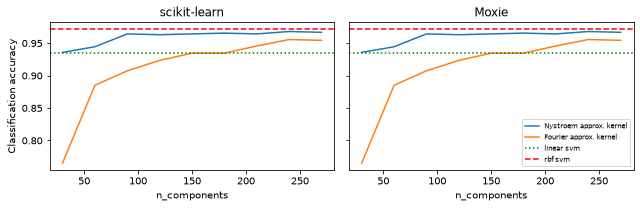

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
RBFSampler.random_weights_ (D=270),PASS,"(64, 270)","(64, 270)",0,0,"rtol=1e-12, atol=1e-15",,same legacy RandomState normal draws scaled by sqrt(2*gamma) in Float64; only the final multiply rounds
RBFSampler.random_offset_ (D=270),PASS,"(270,)","(270,)",0,0,"rtol=1e-12, atol=1e-15",,"same uniform(0, 2*pi) draws"
RBFSampler.transform(test) (D=270),PASS,"(809, 270)","(809, 270)",2.98e-16,2.07e-11,"rtol=0, atol=1e-12",,"64-term dot products in a different summation order (BLAS vs NuMojo matmul) before cos; |phase| <= ~10, so a few ulp of phase error times the 0.086 output scale stays far below 1e-12"
Nystroem.component_indices_ (D=270),PASS,"(270,)","(270,)",,,exact,0 mismatches,
Nystroem.components_ (D=270),PASS,"(270, 64)","(270, 64)",,,exact,0 mismatches,
Nystroem.normalization_ (D=270),PASS,"(270, 270)","(270, 270)",5.83e-13,7.85e-08,"rtol=1e-06, atol=1e-07",,K^-1/2 of a 270x270 RBF Gram via one-sided Jacobi SVD vs LAPACK gesdd; the Gram's condition number amplifies rounding (see docs/kernel_approximation/nystroem/api.md)
Nystroem.transform(test) (D=270),PASS,"(809, 270)","(809, 270)",7.8e-14,4.72e-08,"rtol=1e-06, atol=1e-07",,kernel rows times normalization_.T; inherits the SVD rounding above
RBFSampler + LinearSVC decision_function (D=270),PASS,"(809, 9)","(809, 9)",1.31e-08,8.84e-07,"rtol=1e-05, atol=1e-05",,liblinear dual coordinate descent stops at tol=1e-4 on the same features and permutation seed; 1e-12 feature differences can change the stopping iterate slightly
Nystroem + LinearSVC decision_function (D=270),PASS,"(809, 9)","(809, 9)",1.09e-09,2.29e-07,"rtol=0.0001, atol=0.0001",,"as above, on features that already differ by up to ~1e-7"
"RBFSampler pipeline accuracy, D=30..270",PASS,"(9,)","(9,)",0,0,"rtol=0, atol=0.00185414",,accuracy is a count over 809 test samples; tiny decision differences may flip at most one tie-close sample


In [6]:
mx = nb.results["kernel_approximation"]
clip = nb.results["nystroem_clip"]
moxie_nb.side_by_side(
    sklearn=np.column_stack([sample_sizes, fourier_scores, nystroem_scores]),
    moxie=np.column_stack([sample_sizes, mx["fourier_scores"], mx["nystroem_scores"]]),
)

fig, axes = plt.subplots(1, 2, figsize=(9, 3), dpi=72, sharey=True)
for ax, title, f, n in [(axes[0], "scikit-learn", fourier_scores, nystroem_scores),
                        (axes[1], "Moxie", mx["fourier_scores"], mx["nystroem_scores"])]:
    ax.plot(sample_sizes, n, label="Nystroem approx. kernel")
    ax.plot(sample_sizes, f, label="Fourier approx. kernel")
    ax.axhline(linear_svm_score if title == "scikit-learn" else mx["baseline_scores"][1], ls=":", c="g", label="linear svm")
    ax.axhline(kernel_svm_score if title == "scikit-learn" else mx["baseline_scores"][0], ls="--", c="r", label="rbf svm")
    ax.set_title(title); ax.set_xlabel("n_components")
axes[0].set_ylabel("Classification accuracy"); axes[1].legend(loc="lower right", fontsize=7)
plt.tight_layout(); plt.show()

nb.compare("RBFSampler.random_weights_ (D=270)", sk_fourier_weights, mx["fourier_weights"], rtol=1e-12, atol=1e-15,
           reason="same legacy RandomState normal draws scaled by sqrt(2*gamma) in Float64; only the final multiply rounds")
nb.compare("RBFSampler.random_offset_ (D=270)", sk_fourier_offset, mx["fourier_offset"], rtol=1e-12, atol=1e-15,
           reason="same uniform(0, 2*pi) draws")
nb.compare("RBFSampler.transform(test) (D=270)", sk_fourier_features, mx["fourier_features"], rtol=0, atol=1e-12,
           reason="64-term dot products in a different summation order (BLAS vs NuMojo matmul) before cos; "
                  "|phase| <= ~10, so a few ulp of phase error times the 0.086 output scale stays far below 1e-12")
nb.compare("Nystroem.component_indices_ (D=270)", sk_nys_indices, mx["nys_indices"], exact=True)
nb.compare("Nystroem.components_ (D=270)", sk_nys_components, mx["nys_components"], exact=True)
nb.compare("Nystroem.normalization_ (D=270)", sk_nys_normalization, mx["nys_normalization"], rtol=1e-6, atol=1e-7,
           reason="K^-1/2 of a 270x270 RBF Gram via one-sided Jacobi SVD vs LAPACK gesdd; the Gram's condition "
                  "number amplifies rounding (see docs/kernel_approximation/nystroem/api.md)")
nb.compare("Nystroem.transform(test) (D=270)", sk_nys_features, mx["nys_features"], rtol=1e-6, atol=1e-7,
           reason="kernel rows times normalization_.T; inherits the SVD rounding above")
nb.compare("RBFSampler + LinearSVC decision_function (D=270)", sk_fourier_decision, mx["fourier_decision"], rtol=1e-5, atol=1e-5,
           reason="liblinear dual coordinate descent stops at tol=1e-4 on the same features and permutation seed; "
                  "1e-12 feature differences can change the stopping iterate slightly")
nb.compare("Nystroem + LinearSVC decision_function (D=270)", sk_nys_decision, mx["nys_decision"], rtol=1e-4, atol=1e-4,
           reason="as above, on features that already differ by up to ~1e-7")
nb.compare("RBFSampler pipeline accuracy, D=30..270", np.array(fourier_scores), mx["fourier_scores"], rtol=0, atol=1.5 / len(targets_test),
           reason="accuracy is a count over 809 test samples; tiny decision differences may flip at most one tie-close sample")
nb.compare("Nystroem pipeline accuracy, D=30..270", np.array(nystroem_scores), mx["nystroem_scores"], rtol=0, atol=1.5 / len(targets_test),
           reason="as above")
nb.compare("exact SVC(gamma=0.2) decision_function", sk_kernel_decision, mx["kernel_decision"], rtol=1e-5, atol=1e-5,
           reason="same libsvm SMO stopping at tol=1e-3; floating-point summation order differs")
nb.compare("SVC / LinearSVC accuracy", np.array([kernel_svm_score, linear_svm_score]), mx["baseline_scores"], rtol=0,
           atol=1.5 / len(targets_test), reason="count over 809 test samples, see above")
nb.compare("Nystroem n_components > n_samples warning", sk_warning, list(clip["warnings"]), exact=True)
nb.compare("Nystroem clipped component_indices_", sk_big_indices, clip["indices"], exact=True)
nb.compare("Nystroem clipped transform", sk_big_features, clip["features"], rtol=1e-6, atol=1e-7,
           reason="50x50 RBF Gram inverse square root via Jacobi SVD vs LAPACK, as above")
nb.compare("get_feature_names_out (RBFSampler D=270 + clipped Nystroem)", sk_names, list(clip["names"]), exact=True)
nb.note("set_params(feature_map__n_components=D)", "ADAPTED",
        "typed nested Params record: params.transformer.n_components = D (docs/interfaces.md, Explicit Mojo differences)")
nb.note("Nystroem n_components > n_samples warning", "ADAPTED",
        "Python UserWarning becomes the identical message in Nystroem.fit_warnings (docs/kernel_approximation/nystroem/api.md)")
nb.note("PCA decision-surface figure", "SKIP",
        "plotting-only section of the example; decision_function parity above covers the fitted pipelines")
nb.report()
nb.assert_parity()